# Análisis exploratorio de las imágenes satelitales pentadales

**Archivo reconstruido:** el notebook anterior no quedó disponible en la Papelera. Esta versión reconstruye el análisis a partir de las imágenes TIFF originales y de las gráficas satelitales que permanecieron en el proyecto.

El análisis es exclusivamente satelital. No carga estaciones terrestres, no crea pares satélite–estación y no modifica ninguna imagen. Los valores se describen en su escala original porque la carpeta no incluye metadatos externos que autoricen otra conversión.


## 1. Preparación y ruta de trabajo


In [1]:
%matplotlib inline
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

ROOT = Path.cwd()
SAT_DIR = ROOT / 'ImagenesSatelitePentadal' / 'ImagenesSatelitePentadal'
if not SAT_DIR.exists():
    ROOT = Path(r'E:\Proyecto_final_AnalíticaDeDatos')
    SAT_DIR = ROOT / 'ImagenesSatelitePentadal' / 'ImagenesSatelitePentadal'
GRAPH_DIR = ROOT / 'graficas_satelitales'
GRAPH_DIR.mkdir(exist_ok=True)
print(SAT_DIR)


E:\Proyecto_final_AnalíticaDeDatos\ImagenesSatelitePentadal\ImagenesSatelitePentadal


## 2. Inventario de archivos y lectura del nombre

El nombre esperado es `pptAAAAPP.tif`, donde `AAAA` es el año y `PP` la péntada. Los archivos que comienzan por `._` son metadatos auxiliares creados por macOS y no son imágenes TIFF válidas. Se reportan, pero no se intentan analizar como rasters.


In [2]:
todos_tif = sorted(SAT_DIR.glob('*.tif'))
archivos_auxiliares = [p for p in todos_tif if p.name.startswith('._')]
archivos_reales = [p for p in todos_tif if not p.name.startswith('._')]
patron = re.compile(r'^ppt(?P<year>\d{4})(?P<pentad>\d{2})\.tif$', re.IGNORECASE)

registros = []
nombres_no_validos = []
for ruta in archivos_reales:
    coincidencia = patron.match(ruta.name)
    if coincidencia is None:
        nombres_no_validos.append(ruta.name)
        continue
    registros.append({
        'archivo': ruta.name,
        'ruta': ruta,
        'year': int(coincidencia.group('year')),
        'pentad': int(coincidencia.group('pentad')),
    })
inventario = pd.DataFrame(registros).sort_values(['year', 'pentad']).reset_index(drop=True)

resumen_archivos = pd.DataFrame({
    'categoria': ['archivos .tif encontrados', 'TIFF reales con nombre válido', 'auxiliares ._ ignorados', 'nombres reales no válidos'],
    'cantidad': [len(todos_tif), len(inventario), len(archivos_auxiliares), len(nombres_no_validos)]
})
display(resumen_archivos)
display(inventario.head())
display(inventario.tail())


,categoria,cantidad
0,archivos .tif encontrados,4656
1,TIFF reales con nombre válido,2328
2,auxiliares ._ ignorados,2328
3,nombres reales no válidos,0


,archivo,ruta,year,pentad
0,ppt198101.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,1981,1
1,ppt198102.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,1981,2
2,ppt198103.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,1981,3
3,ppt198104.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,1981,4
4,ppt198105.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,1981,5


,archivo,ruta,year,pentad
2323,ppt201320.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,2013,20
2324,ppt201321.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,2013,21
2325,ppt201322.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,2013,22
2326,ppt201323.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,2013,23
2327,ppt201324.tif,E:\Proyecto_final_AnalíticaDeDatos\ImagenesSat...,2013,24


## 3. Cobertura temporal

Un año pentadal completo contiene 72 imágenes. Esta sección comprueba duplicados, péntadas fuera de rango y secuencias faltantes por año.


In [3]:
duplicados_temporales = inventario.duplicated(['year', 'pentad'], keep=False)
fuera_de_rango = ~inventario.pentad.between(1, 72)
cobertura = (inventario.groupby('year', as_index=False)
             .agg(pentadas=('pentad', 'nunique'), primera=('pentad', 'min'), ultima=('pentad', 'max')))
cobertura['faltantes'] = cobertura.apply(
    lambda fila: sorted(set(range(1, 73)).difference(
        inventario.loc[inventario.year.eq(fila.year), 'pentad']
    )), axis=1
)
cobertura['anio_completo'] = cobertura.pentadas.eq(72) & cobertura.primera.eq(1) & cobertura.ultima.eq(72)

print(f'Duplicados año–péntada: {int(duplicados_temporales.sum()):,}')
print(f'Péntadas fuera de 1–72: {int(fuera_de_rango.sum()):,}')
display(cobertura)


Duplicados año–péntada: 0
Péntadas fuera de 1–72: 0


,year,pentadas,primera,ultima,faltantes,anio_completo
0,1981,72,1,72,[],True
1,1982,72,1,72,[],True
2,1983,72,1,72,[],True
3,1984,72,1,72,[],True
4,1985,72,1,72,[],True
5,1986,72,1,72,[],True
6,1987,72,1,72,[],True
7,1988,72,1,72,[],True
8,1989,72,1,72,[],True
9,1990,72,1,72,[],True


## 4. Estructura espacial y metadatos del raster

Se inspeccionan forma, resolución, extensión, sistema de coordenadas y valor nodata a partir de las etiquetas GeoTIFF. Después se verifica que todas las imágenes tengan la misma estructura.


In [4]:
ruta_muestra = inventario.iloc[0].ruta
with Image.open(ruta_muestra) as imagen:
    muestra = np.asarray(imagen)
    etiquetas = imagen.tag_v2
    ancho, alto = imagen.size
    escala = tuple(etiquetas.get(33550, (np.nan, np.nan, np.nan)))
    amarre = tuple(etiquetas.get(33922, (np.nan,) * 6))
    nodata_texto = etiquetas.get(42113, '-9999')
    geokeys = tuple(etiquetas.get(34735, ()))

res_x, res_y = float(escala[0]), float(escala[1])
xmin, ymax = float(amarre[3]), float(amarre[4])
xmax, ymin = xmin + ancho * res_x, ymax - alto * res_y
nodata = float(nodata_texto)
crs_epsg = 4326 if 4326 in geokeys else None

estructura_muestra = pd.DataFrame({
    'propiedad': ['archivo', 'filas', 'columnas', 'dtype', 'resolución X', 'resolución Y', 'xmin', 'xmax', 'ymin', 'ymax', 'nodata', 'EPSG'],
    'valor': [ruta_muestra.name, alto, ancho, str(muestra.dtype), res_x, res_y, xmin, xmax, ymin, ymax, nodata, crs_epsg]
})
display(estructura_muestra)


,propiedad,valor
0,archivo,ppt198101.tif
1,filas,39
2,columnas,37
3,dtype,int32
4,resolución X,0.050
5,resolución Y,0.050
6,xmin,-77.550
7,xmax,-75.700
8,ymin,3.050
9,ymax,5.000


## 5. Lectura completa y consistencia técnica

Las imágenes son pequeñas, por lo que se leen en memoria para comprobar dimensiones y calcular estadísticas. El valor nodata se transforma únicamente en `NaN` dentro del análisis; los TIFF originales no se modifican.


In [5]:
capas = []
estadisticas = []
formas = set()
modos = set()
for fila in inventario.itertuples(index=False):
    with Image.open(fila.ruta) as imagen:
        arreglo = np.asarray(imagen).astype('float32')
        formas.add(arreglo.shape)
        modos.add(imagen.mode)
    arreglo[arreglo.eq(nodata) if hasattr(arreglo, 'eq') else arreglo == nodata] = np.nan
    capas.append(arreglo)
    estadisticas.append({
        'year': fila.year, 'pentad': fila.pentad,
        'media_regional': float(np.nanmean(arreglo)),
        'minimo': float(np.nanmin(arreglo)),
        'maximo': float(np.nanmax(arreglo)),
        'celdas_nodata': int(np.isnan(arreglo).sum()),
    })
stack = np.stack(capas)
estadisticas_imagen = pd.DataFrame(estadisticas)

consistencia = pd.DataFrame({
    'control': ['formas distintas', 'modos de imagen', 'capas en stack', 'filas', 'columnas', 'celdas nodata totales'],
    'resultado': [len(formas), ', '.join(sorted(modos)), stack.shape[0], stack.shape[1], stack.shape[2], int(np.isnan(stack).sum())]
})
display(consistencia)


,control,resultado
0,formas distintas,1
1,modos de imagen,I
2,capas en stack,2328
3,filas,39
4,columnas,37
5,celdas nodata totales,0


## 6. Distribución de los valores


In [6]:
valores_validos = stack[np.isfinite(stack)]
cuantiles = pd.Series(valores_validos).quantile([0, .01, .05, .25, .50, .75, .95, .99, .999, 1]).to_frame('valor_escala_original')
cuantiles.index.name = 'cuantil'
resumen_valores = pd.DataFrame({
    'metrica': ['celdas válidas', 'celdas nodata', 'ceros', 'negativos', 'media', 'desviación estándar'],
    'valor': [len(valores_validos), int(np.isnan(stack).sum()), int(np.sum(valores_validos == 0)), int(np.sum(valores_validos < 0)), float(np.mean(valores_validos)), float(np.std(valores_validos))]
})
display(resumen_valores)
display(cuantiles)


,metrica,valor
0,celdas válidas,"3,359,304.000"
1,celdas nodata,0.000
2,ceros,7.000
3,negativos,0.000
4,media,48.934
5,desviación estándar,35.835


,valor_escala_original
cuantil,
0.000,0.000
0.010,4.000
0.050,8.000
0.250,22.000
0.500,40.000
0.750,68.000
0.950,120.000
0.990,163.000
0.999,200.000


## 7. Ciclo pentadal y acumulados anuales

Los cálculos climatológicos y anuales usan solamente 1981–2012, porque son los años con las 72 péntadas. El año 2013 se conserva en el inventario, pero no se compara como si fuera un año completo.


In [7]:
ANIO_INICIO_PROYECTO, ANIO_FIN_PROYECTO = 1981, 2003
LIMITES_PARTICION = {
    'entrenamiento': (1981, 1995),
    'validación': (1996, 2000),
    'prueba': (2001, 2003),
}

inventario_proyecto = inventario.loc[inventario.year.between(ANIO_INICIO_PROYECTO, ANIO_FIN_PROYECTO)].copy()
anios_proyecto = list(range(ANIO_INICIO_PROYECTO, ANIO_FIN_PROYECTO + 1))
anios_completos = cobertura.loc[
    cobertura.year.isin(anios_proyecto) & cobertura.anio_completo, 'year'
].tolist()
temporal_proyecto = estadisticas_imagen.loc[estadisticas_imagen.year.isin(anios_completos)].copy()
matriz_temporal = (temporal_proyecto
                   .pivot(index='year', columns='pentad', values='media_regional')
                   .sort_index().sort_index(axis=1))
ciclo_media = matriz_temporal.loc[1981:1995].mean(axis=0)  # climatología descriptiva ajustada en train
ciclo_q25 = matriz_temporal.loc[1981:1995].quantile(.25, axis=0)
ciclo_q75 = matriz_temporal.loc[1981:1995].quantile(.75, axis=0)
acumulado_anual_regional = matriz_temporal.sum(axis=1)

indices_proyecto = inventario.index[inventario.year.between(ANIO_INICIO_PROYECTO, ANIO_FIN_PROYECTO)].to_numpy()
valores_validos_proyecto = stack[indices_proyecto]
valores_validos_proyecto = valores_validos_proyecto[np.isfinite(valores_validos_proyecto)]

resumen_temporal = pd.DataFrame({
    'metrica': [
        'años oficiales', 'primer año', 'último año', 'años completos',
        'péntadas por año', 'imágenes dentro del proyecto'
    ],
    'valor': [
        len(anios_proyecto), ANIO_INICIO_PROYECTO, ANIO_FIN_PROYECTO,
        len(anios_completos), matriz_temporal.shape[1], len(inventario_proyecto)
    ]
})
display(resumen_temporal)
display(acumulado_anual_regional.describe().to_frame('acumulado_regional_1981_2003'))


,metrica,valor
0,años oficiales,23
1,primer año,1981
2,último año,2003
3,años completos,23
4,péntadas por año,72
5,imágenes dentro del proyecto,1656


,acumulado_regional_1981_2003
count,23.000
mean,"3,492.695"
std,213.954
min,"2,907.293"
25%,"3,398.639"
50%,"3,567.875"
75%,"3,633.012"
max,"3,776.757"


## 8. Diagnóstico temporal


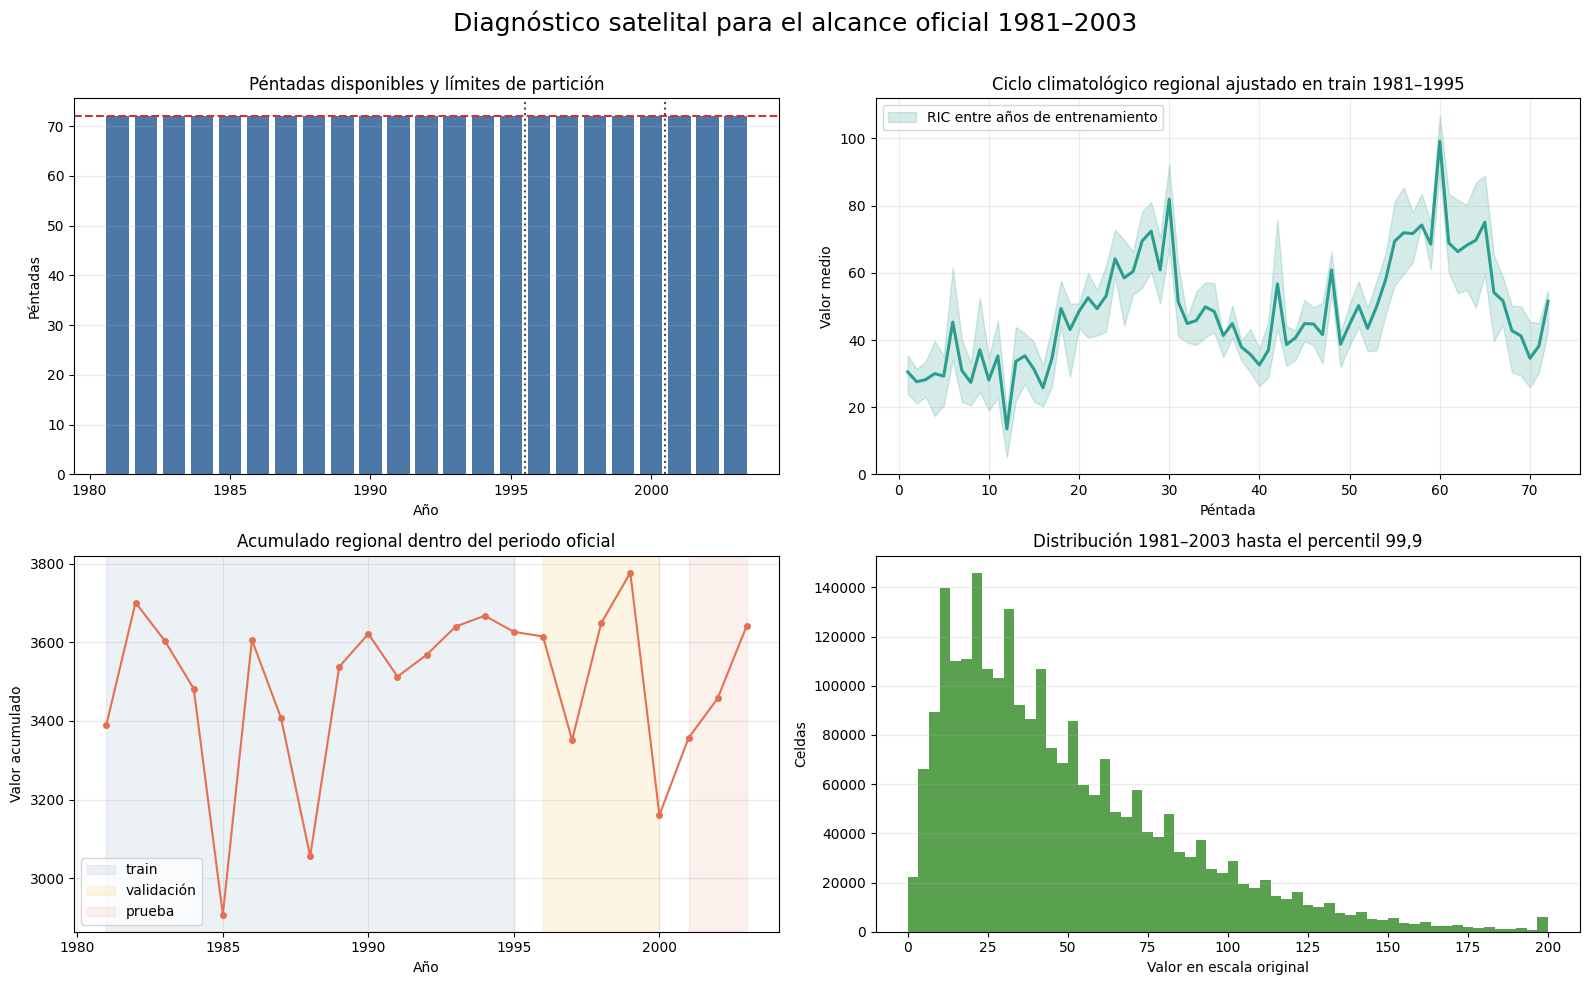

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Diagnóstico satelital para el alcance oficial 1981–2003', fontsize=18)
cobertura_graf = cobertura.loc[cobertura.year.between(1981, 2003)]
axes[0, 0].bar(cobertura_graf.year, cobertura_graf.pentadas, color='#4c78a8')
axes[0, 0].axhline(72, color='#c33', linestyle='--')
axes[0, 0].axvline(1995.5, color='black', linestyle=':', alpha=.7)
axes[0, 0].axvline(2000.5, color='black', linestyle=':', alpha=.7)
axes[0, 0].set(title='Péntadas disponibles y límites de partición', xlabel='Año', ylabel='Péntadas')
axes[0, 0].grid(axis='y', alpha=.25)

x = ciclo_media.index.to_numpy()
axes[0, 1].plot(x, ciclo_media.to_numpy(), color='#2a9d8f', linewidth=2.2)
axes[0, 1].fill_between(x, ciclo_q25.to_numpy(), ciclo_q75.to_numpy(), color='#2a9d8f', alpha=.2,
                        label='RIC entre años de entrenamiento')
axes[0, 1].set(title='Ciclo climatológico regional ajustado en train 1981–1995',
               xlabel='Péntada', ylabel='Valor medio')
axes[0, 1].legend()
axes[0, 1].grid(alpha=.25)

axes[1, 0].plot(acumulado_anual_regional.index, acumulado_anual_regional.values,
                color='#e76f51', marker='o', markersize=4)
axes[1, 0].axvspan(1981, 1995, color='#4c78a8', alpha=.10, label='train')
axes[1, 0].axvspan(1996, 2000, color='#f2c14e', alpha=.15, label='validación')
axes[1, 0].axvspan(2001, 2003, color='#e76f51', alpha=.10, label='prueba')
axes[1, 0].set(title='Acumulado regional dentro del periodo oficial', xlabel='Año', ylabel='Valor acumulado')
axes[1, 0].legend()
axes[1, 0].grid(alpha=.25)

limite = np.quantile(valores_validos_proyecto, .999)
axes[1, 1].hist(valores_validos_proyecto[valores_validos_proyecto <= limite], bins=60, color='#59a14f')
axes[1, 1].set(title='Distribución 1981–2003 hasta el percentil 99,9',
               xlabel='Valor en escala original', ylabel='Celdas')
axes[1, 1].grid(axis='y', alpha=.25)

plt.tight_layout(rect=[0, 0, 1, .97])
fig.savefig(GRAPH_DIR / 'resumen_diagnostico_satelital.png', dpi=160, bbox_inches='tight')
plt.show()


## 9. Climatología espacial del acumulado anual


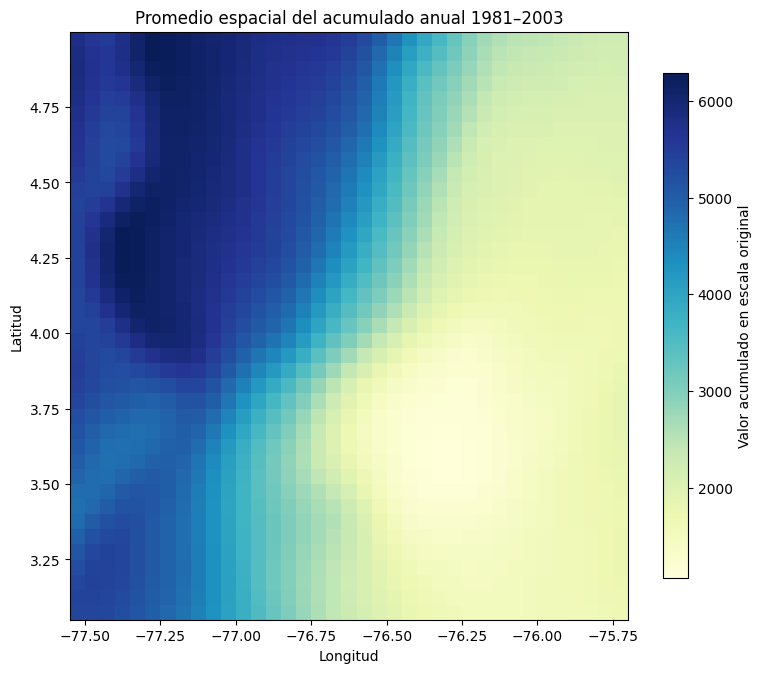

In [9]:
acumulados_por_anio = []
for anio in anios_completos:
    indices = inventario.index[inventario.year.eq(anio)].to_numpy()
    acumulados_por_anio.append(np.nansum(stack[indices], axis=0))
climatologia_acumulado = np.nanmean(np.stack(acumulados_por_anio), axis=0)

fig, ax = plt.subplots(figsize=(9, 8))
imagen = ax.imshow(climatologia_acumulado, extent=[xmin, xmax, ymin, ymax],
                   origin='upper', cmap='YlGnBu')
ax.set(title='Promedio espacial del acumulado anual 1981–2003',
       xlabel='Longitud', ylabel='Latitud')
barra = fig.colorbar(imagen, ax=ax, shrink=.82)
barra.set_label('Valor acumulado en escala original')
fig.savefig(GRAPH_DIR / 'mapa_climatologia_satelital.png', dpi=160, bbox_inches='tight')
plt.show()


## 10. Hallazgos automáticos


In [10]:
def particion_de_anio(year):
    if 1981 <= year <= 1995:
        return 'entrenamiento'
    if 1996 <= year <= 2000:
        return 'validación'
    if 2001 <= year <= 2003:
        return 'prueba'
    return 'fuera del proyecto'

inventario['particion_proyecto'] = inventario.year.map(particion_de_anio)
estadisticas_imagen['particion_proyecto'] = estadisticas_imagen.year.map(particion_de_anio)
resumen_particiones = (inventario_proyecto.assign(particion=lambda d: d.year.map(particion_de_anio))
                       .groupby('particion', as_index=False)
                       .agg(anio_inicial=('year', 'min'), anio_final=('year', 'max'),
                            anios=('year', 'nunique'), imagenes=('archivo', 'size'),
                            pentadas_minimas=('pentad', 'nunique')))

filas_tope = []
for nombre, (inicio, fin) in LIMITES_PARTICION.items():
    idx = inventario.index[inventario.year.between(inicio, fin)].to_numpy()
    valores = stack[idx]
    filas_tope.append({
        'particion': nombre,
        'capas': len(idx),
        'celdas': int(valores.size),
        'celdas_igual_200': int(np.sum(valores == 200)),
        'porcentaje_igual_200': 100 * float(np.mean(valores == 200)),
    })
diagnostico_tope = pd.DataFrame(filas_tope)

hallazgos = [
    f'El inventario completo contiene {len(inventario):,} TIFF reales; el proyecto usa {len(inventario_proyecto):,} imágenes de 1981 a 2003.',
    'Los 23 años oficiales tienen exactamente 72 péntadas, sin duplicados ni capas faltantes.',
    f'Todas las imágenes comparten una malla de {alto}×{ancho}, resolución {res_x:.2f}° y EPSG {crs_epsg}.',
    f'En 1981–2003 no hay nodata ni negativos; los valores válidos van de {valores_validos_proyecto.min():,.0f} a {valores_validos_proyecto.max():,.0f}.',
    'El valor 200 aparece con una frecuencia no despreciable y se conserva como señal de posible techo; no se corrige sin documentación del producto.',
    'El ciclo climatológico usado como referencia descriptiva se calcula solo con entrenamiento 1981–1995.',
    'Este EDA todavía no extrae píxeles por estación: faltan coordenadas, altitud y una regla documentada de asignación estación–píxel.',
]
display(Markdown('\n'.join(f'- {texto}' for texto in hallazgos)))
display(resumen_particiones)
display(diagnostico_tope)


- El inventario completo contiene 2,328 TIFF reales; el proyecto usa 1,656 imágenes de 1981 a 2003.
- Los 23 años oficiales tienen exactamente 72 péntadas, sin duplicados ni capas faltantes.
- Todas las imágenes comparten una malla de 39×37, resolución 0.05° y EPSG 4326.
- En 1981–2003 no hay nodata ni negativos; los valores válidos van de 0 a 200.
- El valor 200 aparece con una frecuencia no despreciable y se conserva como señal de posible techo; no se corrige sin documentación del producto.
- El ciclo climatológico usado como referencia descriptiva se calcula solo con entrenamiento 1981–1995.
- Este EDA todavía no extrae píxeles por estación: faltan coordenadas, altitud y una regla documentada de asignación estación–píxel.

,particion,anio_inicial,anio_final,anios,imagenes,pentadas_minimas
0,entrenamiento,1981,1995,15,1080,72
1,prueba,2001,2003,3,216,72
2,validación,1996,2000,5,360,72


,particion,capas,celdas,celdas_igual_200,porcentaje_igual_200
0,entrenamiento,1080,1558440,3470,0.223
1,validación,360,519480,839,0.162
2,prueba,216,311688,829,0.266


## Conclusión actualizada

El insumo satelital está completo para los **23 años oficiales, 1981–2003**, con 72 péntadas por año y una malla espacial constante. La partición temporal queda fijada en entrenamiento 1981–1995, validación 1996–2000 y prueba 2001–2003. Las imágenes posteriores a 2003 se conservan en el inventario, pero quedan fuera del modelado supervisado del proyecto.

Antes de entrenar la red faltan tres verificaciones: documentar las unidades y el posible techo en 200, confirmar la correspondencia temporal de las 72 péntadas y obtener coordenadas/altitud para construir pares estación–píxel. Ninguna diferencia satélite–estación se usará para cambiar automáticamente un cero terrestre.
